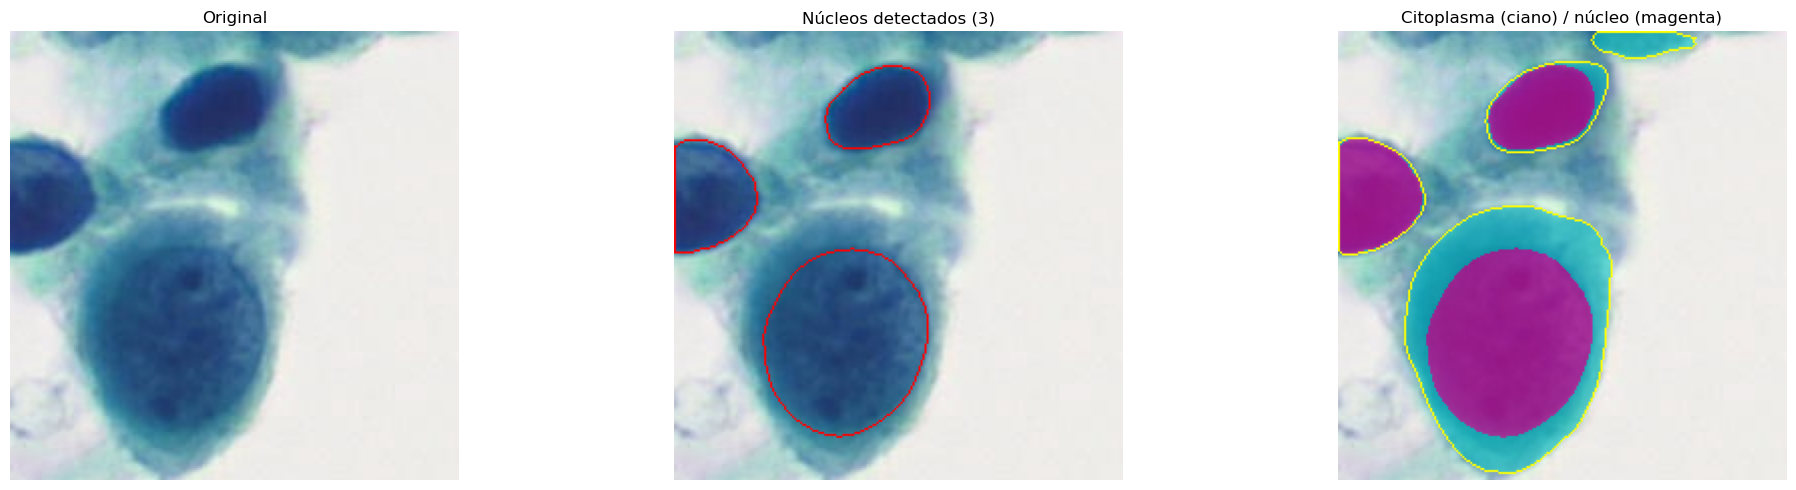

células: 4
núcleos: 3
células com núcleo: 3


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from cellpose import models, utils

img = np.array(Image.open(r"D:\Anaconda\HSIL.png").convert("RGB"))   # [H, W, 3]

cell_model = models.Cellpose(gpu=True, model_type='cyto3')
nuc_model  = models.Cellpose(gpu=True, model_type='nuclei')

cells,  *_ = cell_model.eval(img, diameter=None, channels=[0, 0])
nuclei, *_ = nuc_model.eval(img, diameter=None, channels=[0, 0], invert=True)

# núcleo = pixels de núcleo dentro de alguma célula; citoplasma = resto da célula
nuc_in_cell = (nuclei > 0) & (cells > 0)
cyto = (cells > 0) & ~nuc_in_cell

overlay = img.astype(float) / 255
overlay[cyto]        = 0.5 * overlay[cyto]        + 0.5 * np.array([0.0, 0.8, 0.8])   # ciano
overlay[nuc_in_cell] = 0.4 * overlay[nuc_in_cell] + 0.6 * np.array([0.9, 0.0, 0.6])   # magenta
overlay[utils.masks_to_outlines(cells)] = [1, 1, 0]                                   # contorno amarelo

nuc_view = img.astype(float) / 255
nuc_view[utils.masks_to_outlines(nuclei)] = [1, 0, 0]

fig, ax = plt.subplots(1, 3, figsize=(21, 5))
ax[0].imshow(img);      ax[0].set_title('Original')
ax[1].imshow(nuc_view); ax[1].set_title(f'Núcleos detectados ({nuclei.max()})')
ax[2].imshow(overlay);  ax[2].set_title('Citoplasma (ciano) / núcleo (magenta)')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

print('células:', cells.max())
print('núcleos:', nuclei.max())
print('células com núcleo:', np.unique(cells[nuc_in_cell]).size)


In [23]:
def nuc_ratios(cells,nuclei):
    ratios = []

    # id == 0 (background, não é célula)
    ids_cells = np.unique(cells)
    if ids_cells[0] == 0:
        ids_cells = ids_cells[1:]
    for i in ids_cells:
        # Célula de id == i
        cell = (cells == i)

        # id == 0 (background, não é núcleo) 
        ids_nucleos = np.unique(nuclei[cell])
        if ids_nucleos[0] == 0:
            ids_nucleos = ids_nucleos[1:]

        # Uma célula pode conter mais de um núcleo (consideramos que um núcleo pertence à célula se >50% de sua área está contida nela)
        area_nucleos = 0
        for j in ids_nucleos:
            # Núcleo de id == j
            nuc = (nuclei == j)
            
            area_tot_nuc = nuc.sum()
            # Núcleo de id == j dentro de 'cell'
            area_ins_nuc = (nuclei[cell] == j).sum()
            
            if (area_ins_nuc / area_tot_nuc) > 0.5:
                area_nucleos += area_ins_nuc

        # Ignoramos núcleos com área 0
        if area_nucleos == 0:
            continue
        
        area_cell = cell.sum()
        ratios.append(area_nucleos / area_cell)  
                
    return ratios

In [24]:
print(nuc_ratios(cells,nuclei))

[np.float64(0.7912598791259879), np.float64(0.9385145105755042), np.float64(0.5556174042118935)]
